# Datenanalyse: Gewinn und unverkaufte Ware in einer Bäckerei

**Modul:** Business Analytics / Einführung in die Statistik
**Datensatz:** `bakery_dataset_eur.csv` (synthetischer Bäckerei-Transaktionsdatensatz, Beträge in Euro)
**Ursprungsquelle:** https://github.com/forest0224/bakery-analytics (Excel-Datei mit passendem Namen und Tabellenaufbau).
**Euro-Preise:** Die bereitgestellte EUR-Arbeitsdatei enthält geschätzte Preise, keine verifizierten Marktdaten.

**Google Colab:** Notebook öffnen und Zellen ausführen. Wenn die CSV fehlt, fragt das Notebook automatisch nach dem Upload von `bakery_dataset_eur.csv`.

---

## Worum geht es?

Eine Bäckerei verkauft Waren mit kurzer Haltbarkeit. Was am Abend nicht verkauft ist,
wird oft weggeworfen und verursacht Kosten. In diesem Projekt schauen wir uns an,
**womit die Bäckerei Gewinn macht, wo Verlust entsteht und wie viel Ware übrig bleibt.**

### Unsere Forschungsfragen (einfach formuliert)

1. Welche Produkte und Produktgruppen bringen Gewinn, und bei welchen entsteht eher Verlust?
2. Wie hängen Rabatte mit dem Gewinn und der verkauften Menge zusammen?
3. Bei welchen Produkten bleibt besonders viel Ware übrig?
4. Unterscheiden sich die drei Filialen, die Wochentage oder die Jahreszeiten?

> **Hinweis zu den Daten:** Es handelt sich um einen *synthetischen* (künstlich erzeugten)
> Datensatz. Die Ergebnisse zeigen Muster in diesen Daten, erlauben aber keine sicheren
> Aussagen über echte Bäckereien.


## 1. Vorbereitung: Pakete laden

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

Path("abbildungen").mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("Pakete geladen.")

Pakete geladen.


## 2. Daten einlesen

In [2]:
csv_path = Path("bakery_dataset_eur.csv")
if not csv_path.exists():
    try:
        from google.colab import files
        print("Bitte die Datei bakery_dataset_eur.csv hochladen.")
        uploaded = files.upload()
        if csv_path.name not in uploaded:
            raise FileNotFoundError("Bitte bakery_dataset_eur.csv auswählen und erneut ausführen.")
    except ImportError as exc:
        raise FileNotFoundError("Lege bakery_dataset_eur.csv neben das Notebook oder nutze Google Colab zum Upload.") from exc

df = pd.read_csv(csv_path, parse_dates=["Date"])
print("Zeilen:", len(df), "| Spalten:", df.shape[1])
df.head()

Zeilen: 16569 | Spalten: 41


,Transaction_ID,Date,Time,Customer_ID,Customer_Age,Customer_Gender,Product,Category,Quantity,Unit_Price,...,Promotion_Applied,Promotion_Type,Promotion_Score,Customer_Rating,Customer_Segment,Loyalty_Member,Profit,Waste_Cost,Recommended_Product,Recommended_Discount
0,TXN000038,2023-01-01,07:13:00,CUST01289,32,Male,Rusk,Biscuits & Cookies,1,1.50,...,Yes,Festival,100,4,Young Professional,Yes,-0.18,0.33,Rusk,13.00
1,TXN000039,2023-01-01,07:13:00,CUST01289,32,Male,Peanut Butter,Spreads,4,4.80,...,Yes,Festival,100,4,Young Professional,Yes,-2.86,4.66,Bread,9.00
2,TXN000040,2023-01-01,07:13:00,CUST01289,32,Male,Black Forest Cake,Cakes,2,4.20,...,Yes,Festival,100,4,Young Professional,Yes,-4.32,4.87,Soft Drink,14.70
3,TXN000041,2023-01-01,07:13:00,CUST01289,32,Male,Honey,Spreads,4,6.20,...,Yes,Festival,100,4,Young Professional,Yes,-2.62,6.31,Honey,3.30
4,TXN000043,2023-01-01,08:15:00,CUST01077,17,Female,Tea,Beverages,2,2.60,...,Yes,Festival,100,4,Student,No,-0.06,2.09,Biscuit,25.20


## 3. Erster Überblick über die Daten

In [3]:
print("Zeitraum:", df["Date"].min().date(), "bis", df["Date"].max().date())
print("Produkte:", df["Product"].nunique())
print("Kategorien:", df["Category"].nunique())
print("Filialen:", df["Store_ID"].nunique())
print("Kunden:", df["Customer_ID"].nunique())
print("Verkaufspositionen:", len(df))

Zeitraum: 2023-01-01 bis 2024-12-31


Produkte: 35
Kategorien: 10
Filialen: 3
Kunden: 2173
Verkaufspositionen: 16569


### Fehlende Werte

Zwei Spalten haben viele leere Felder: `Festival` und `Promotion_Type`.
Das ist aber kein Fehler: Ein leeres Feld bedeutet hier schlicht
*kein Festival* bzw. *keine Aktion*. Wir füllen diese Felder entsprechend.

In [4]:
print("Fehlende Werte vor Bereinigung:")
print(df[["Festival", "Promotion_Type"]].isna().sum())

df["Festival"] = df["Festival"].fillna("Kein Festival")
df["Promotion_Type"] = df["Promotion_Type"].fillna("Keine Aktion")

print("\nFehlende Werte in allen Spalten nach Bereinigung:", int(df.isna().sum().sum()))

Fehlende Werte vor Bereinigung:
Festival          15960
Promotion_Type    13209
dtype: int64

Fehlende Werte in allen Spalten nach Bereinigung: 0


## 4. Wichtige Kennzahlen

In [5]:
umsatz = df["Total_Bill"].sum()
gewinn = df["Profit"].sum()
verlustanteil = (df["Profit"] < 0).mean() * 100
verderbquote = df["Unsold_Units"].sum() / df["Units_Produced"].sum() * 100

print(f"Gesamtumsatz:            {umsatz:,.0f} EUR")
print(f"Gesamtgewinn:            {gewinn:,.0f} EUR")
print(f"Durchschnittliche Rechnung: {df['Total_Bill'].mean():.2f} EUR")
print(f"Durchschnittlicher Gewinn pro Position: {df['Profit'].mean():.2f} EUR")
print(f"Anteil Positionen mit Verlust: {verlustanteil:.1f} %")
print(f"Verderbquote (unverkaufte / produzierte Einheiten): {verderbquote:.1f} %")

Gesamtumsatz:            119,199 EUR
Gesamtgewinn:            -3,539 EUR
Durchschnittliche Rechnung: 7.19 EUR
Durchschnittlicher Gewinn pro Position: -0.21 EUR
Anteil Positionen mit Verlust: 50.3 %
Verderbquote (unverkaufte / produzierte Einheiten): 35.9 %


Die Bäckerei macht in diesen Daten insgesamt **Verlust**, und rund ein Drittel
der produzierten Ware wird nicht verkauft. Woran liegt das? Das schauen wir uns
jetzt anhand der vier Forschungsfragen an.

## 5. Frage 1: Welche Produktgruppen bringen Gewinn, welche Verlust?

Category
Dairy                -1.81
Spreads              -1.70
Cakes                -0.61
Biscuits & Cookies   -0.27
Muffins              -0.22
Bakery Staples       -0.07
Savoury Snacks        0.04
Bakery Snacks         0.11
Cupcakes              0.14
Beverages             1.57
Name: Profit, dtype: float64


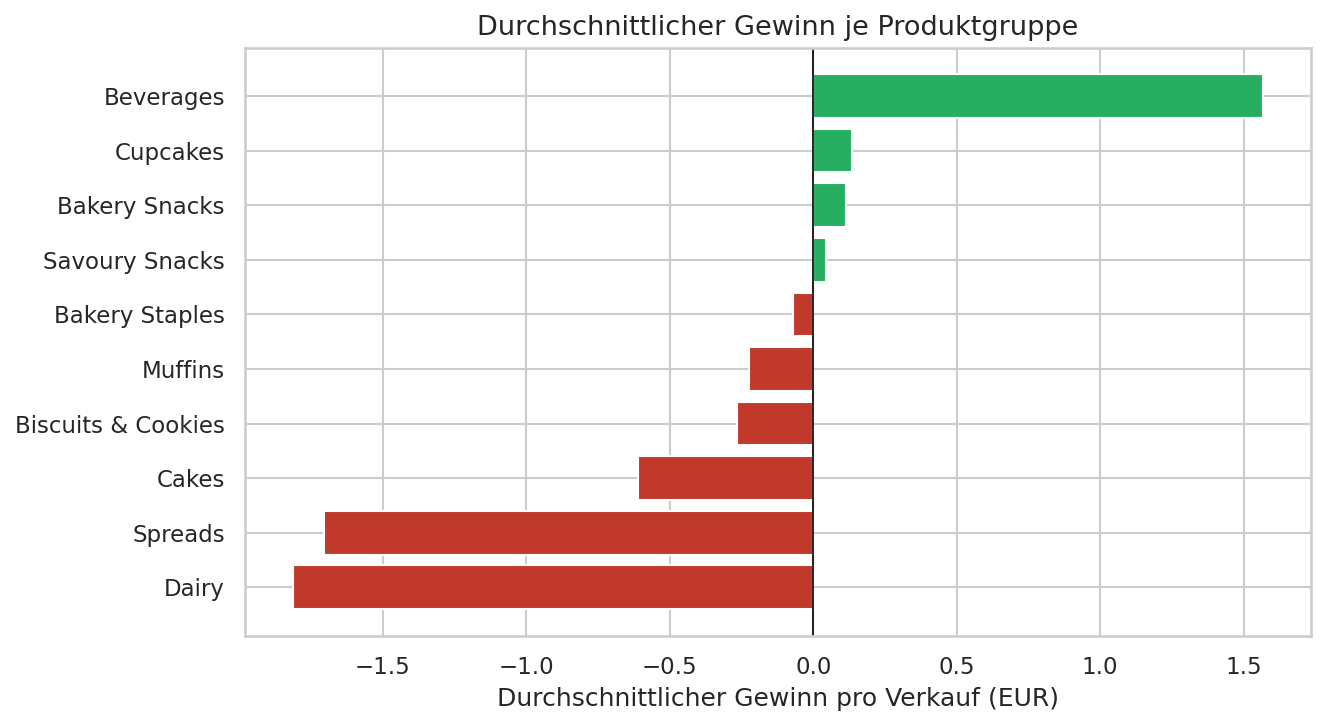

In [6]:
gewinn_kat = df.groupby("Category")["Profit"].mean().sort_values()
print(gewinn_kat.round(2))

fig, ax = plt.subplots()
farben = ["#c0392b" if v < 0 else "#27ae60" for v in gewinn_kat]
ax.barh(gewinn_kat.index, gewinn_kat.values, color=farben)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Durchschnittlicher Gewinn pro Verkauf (EUR)")
ax.set_title("Durchschnittlicher Gewinn je Produktgruppe")
plt.tight_layout()
plt.savefig("abbildungen/01_gewinn_kategorie.png", dpi=130, bbox_inches="tight")
plt.show()

**Lesehilfe:** Grün = im Schnitt Gewinn, Rot = im Schnitt Verlust.
Getränke (*Beverages*) haben den höchsten durchschnittlichen Gewinn. In den Gruppen
*Dairy*, *Spreads* und *Cakes* liegt der durchschnittliche Gewinn unter null. Das zeigt
Unterschiede zwischen den Gruppen, beweist aber nicht, wodurch sie verursacht werden.

## 6. Frage 2: Wie hängen Rabatte mit Gewinn und Menge zusammen?

In [7]:
from scipy.stats import spearmanr

r_gewinn, _ = spearmanr(df["Discount_Percentage"], df["Profit"])
r_menge, _ = spearmanr(df["Discount_Percentage"], df["Quantity"])
print(f"Zusammenhang Rabatt <-> Gewinn: {r_gewinn:+.2f}")
print(f"Zusammenhang Rabatt <-> verkaufte Menge: {r_menge:+.2f}")

mit = df.loc[df["Promotion_Applied"] == "Yes", "Profit"].mean()
ohne = df.loc[df["Promotion_Applied"] == "No", "Profit"].mean()
print(f"\nDurchschnittlicher Gewinn mit Aktion:  {mit:.2f} EUR")
print(f"Durchschnittlicher Gewinn ohne Aktion: {ohne:.2f} EUR")

Zusammenhang Rabatt <-> Gewinn: -0.35
Zusammenhang Rabatt <-> verkaufte Menge: -0.01

Durchschnittlicher Gewinn mit Aktion:  -2.14 EUR
Durchschnittlicher Gewinn ohne Aktion: 0.28 EUR


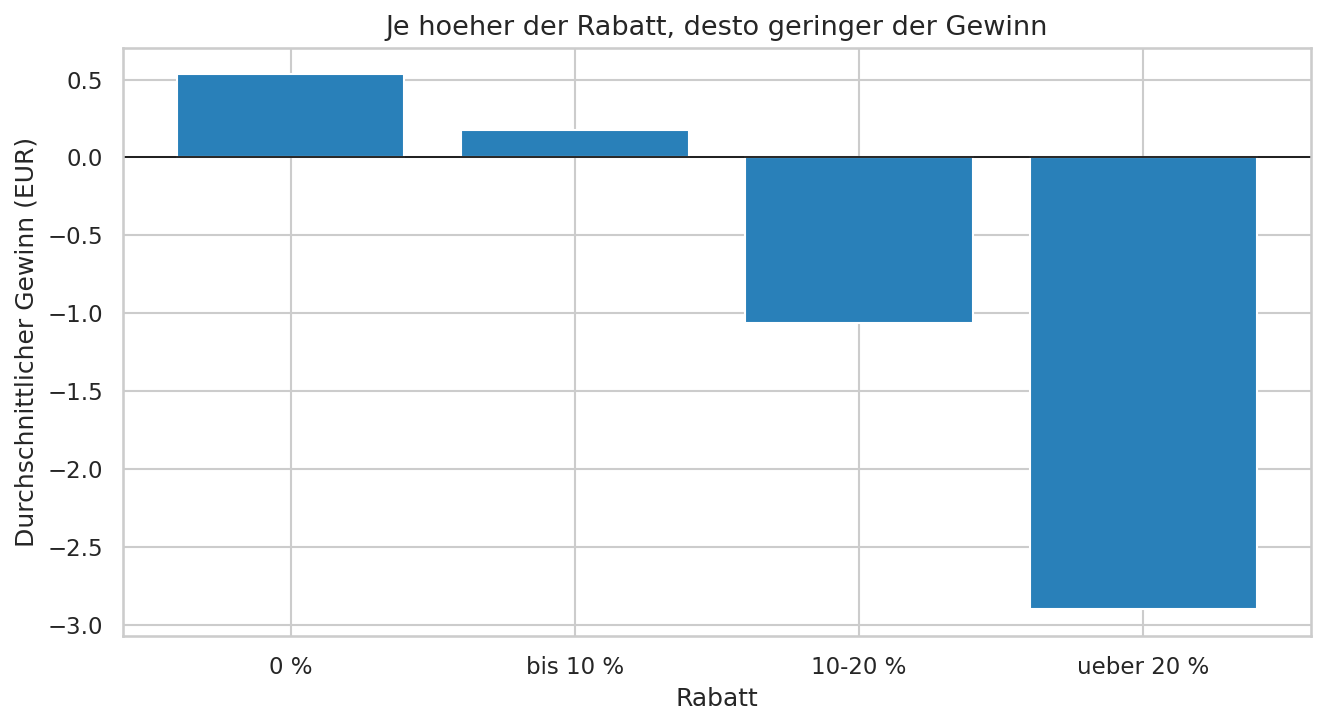

In [8]:
# Gewinn nach Rabattstufe
df["Rabattstufe"] = pd.cut(df["Discount_Percentage"],
                           bins=[-0.1, 0.1, 10, 20, 100],
                           labels=["0 %", "bis 10 %", "10-20 %", "ueber 20 %"])
stufe = df.groupby("Rabattstufe", observed=True)["Profit"].mean()

fig, ax = plt.subplots()
ax.bar(stufe.index.astype(str), stufe.values, color="#2980b9")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Durchschnittlicher Gewinn (EUR)")
ax.set_xlabel("Rabatt")
ax.set_title("Je hoeher der Rabatt, desto geringer der Gewinn")
plt.tight_layout()
plt.savefig("abbildungen/02_rabatt_gewinn.png", dpi=130, bbox_inches="tight")
plt.show()

**Ergebnis:** In diesen Daten besteht ein negativer Zusammenhang zwischen Rabatt und
Gewinn. Der Zusammenhang zwischen Rabatt und verkaufter Menge liegt nahe null. Das
beschreibt Muster in den Daten und beweist nicht, dass Rabatte die Ursache sind.

## 7. Frage 3: Bei welchen Produkten bleibt besonders viel Ware übrig?

Product
Honey               44.40
Biscuit             41.70
Peanut Butter       41.60
Cheese              40.60
Soft Drink          40.60
Rusk                39.70
Jam                 39.20
Cookies             39.10
Brown Bread         38.00
Chocolate Cookies   37.90
Name: Verderbquote, dtype: float64


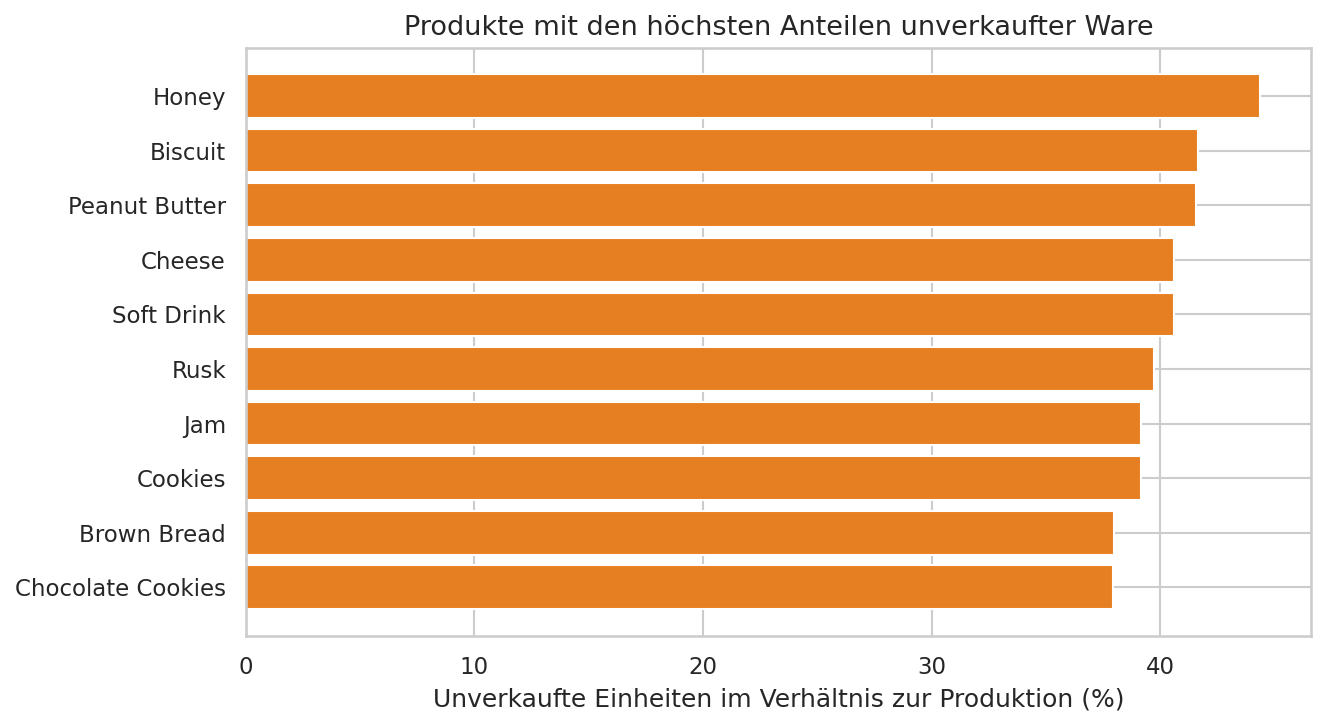

In [9]:
# Gewichtete Verderbquote je Produkt: Summe unverkauft / Summe produziert
rest = df.groupby("Product").agg(
    unverkauft=("Unsold_Units", "sum"),
    produziert=("Units_Produced", "sum")
)
rest["Verderbquote"] = rest["unverkauft"] / rest["produziert"]
top_verderb = rest["Verderbquote"].sort_values(ascending=False).head(10)
print((top_verderb * 100).round(1))

fig, ax = plt.subplots()
ax.barh(top_verderb.index[::-1], (top_verderb.values[::-1] * 100), color="#e67e22")
ax.set_xlabel("Unverkaufte Einheiten im Verhältnis zur Produktion (%)")
ax.set_title("Produkte mit den höchsten Anteilen unverkaufter Ware")
plt.tight_layout()
plt.savefig("abbildungen/03_verderb_produkt.png", dpi=130, bbox_inches="tight")
plt.show()


## 8. Frage 4: Unterschiede zwischen Filialen, Wochentagen und Jahreszeiten

In [10]:
print("Durchschnittlicher Gewinn je Filiale:")
print(df.groupby("Store_ID")["Profit"].mean().round(2))
print("\nDurchschnittlicher Gewinn je Jahreszeit:")
print(df.groupby("Season")["Profit"].mean().round(2))
print("\nDurchschnittlicher Gewinn je Wochentag:")
print(df.groupby("Day_of_Week")["Profit"].mean().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
).round(2))


Durchschnittlicher Gewinn je Filiale:
Store_ID
ST01   -0.19
ST02   -0.26
ST03   -0.19
Name: Profit, dtype: float64

Durchschnittlicher Gewinn je Jahreszeit:
Season
Autumn    -0.33
Monsoon   -0.14
Summer    -0.23
Winter    -0.21
Name: Profit, dtype: float64

Durchschnittlicher Gewinn je Wochentag:
Day_of_Week
Monday      -0.18
Tuesday      0.04
Wednesday   -0.04
Thursday     0.07
Friday       0.28
Saturday    -0.37
Sunday      -0.65
Name: Profit, dtype: float64


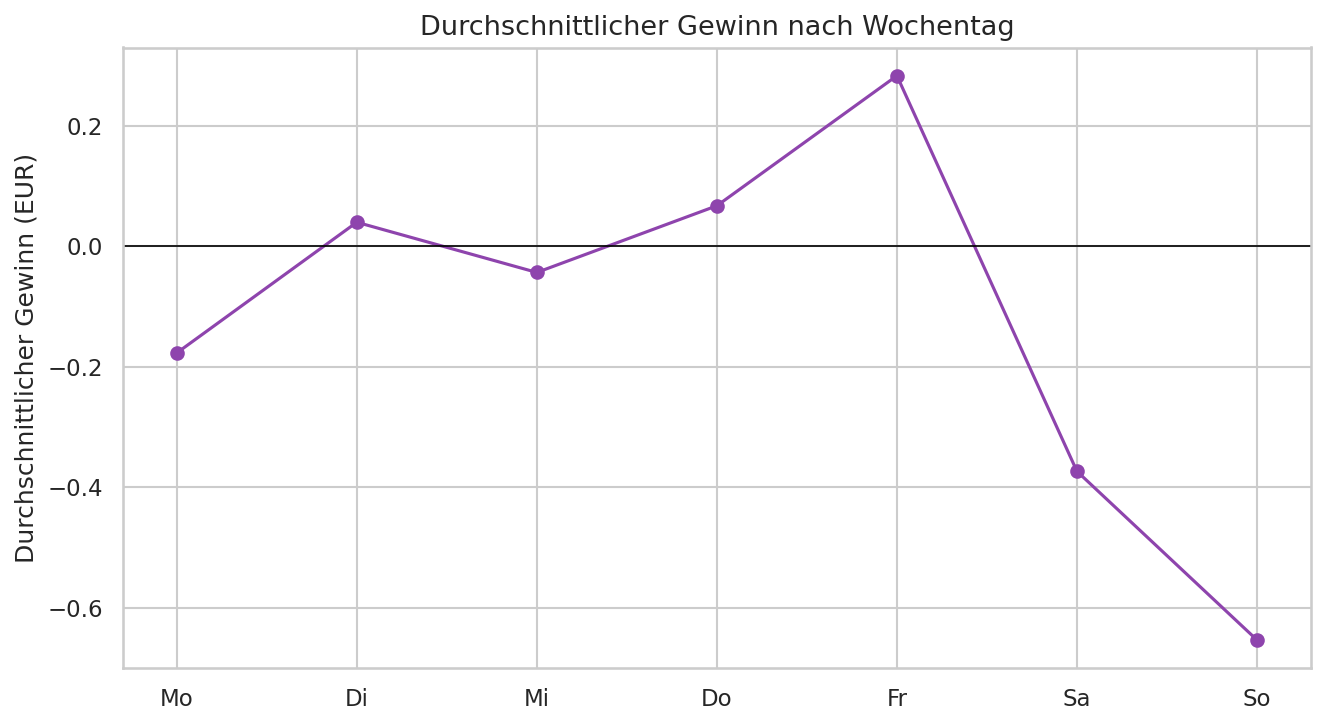

In [11]:
reihenfolge = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
tag = df.groupby("Day_of_Week")["Profit"].mean().reindex(reihenfolge)

fig, ax = plt.subplots()
ax.plot(["Mo","Di","Mi","Do","Fr","Sa","So"], tag.values, marker="o", color="#8e44ad")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Durchschnittlicher Gewinn (EUR)")
ax.set_title("Durchschnittlicher Gewinn nach Wochentag")
plt.tight_layout()
plt.savefig("abbildungen/04_wochentag.png", dpi=130, bbox_inches="tight")
plt.show()

Die durchschnittlichen Gewinne der Filialen liegen nahe beieinander. Bei Wochentagen
und Jahreszeiten unterscheiden sich die Mittelwerte ebenfalls. Diese Vergleiche sind
beschreibend; wir testen hier nicht, ob die Unterschiede statistisch signifikant sind.

## 9. Zeitlicher Verlauf von Umsatz und Gewinn

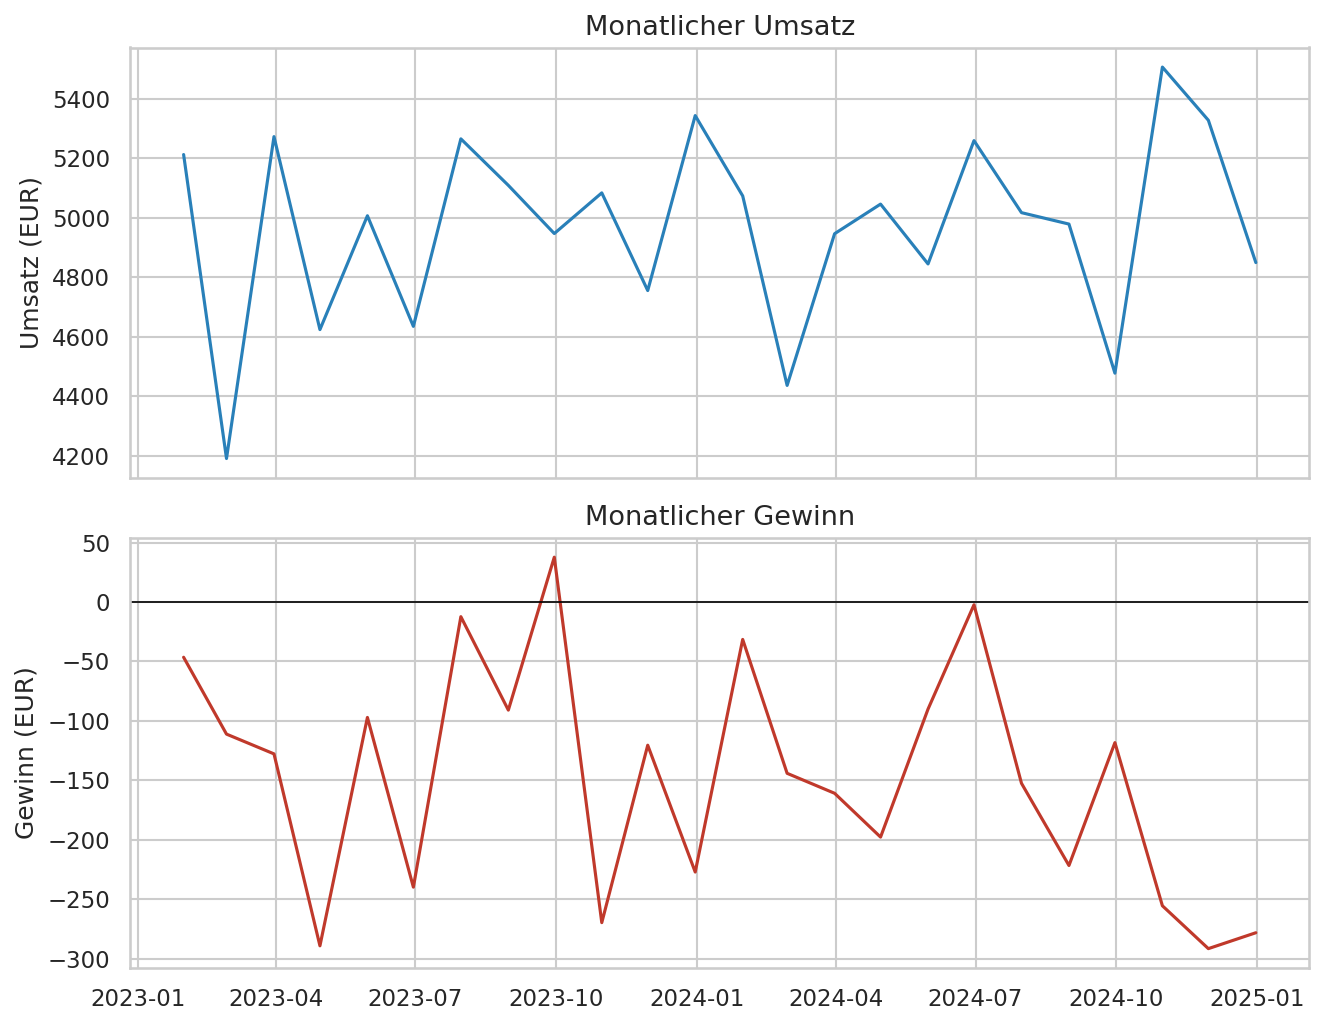

In [12]:
monat = df.set_index("Date").resample("ME")[["Total_Bill", "Profit"]].sum()

fig, ax = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax[0].plot(monat.index, monat["Total_Bill"], color="#2980b9")
ax[0].set_ylabel("Umsatz (EUR)")
ax[0].set_title("Monatlicher Umsatz")
ax[1].plot(monat.index, monat["Profit"], color="#c0392b")
ax[1].axhline(0, color="black", linewidth=0.8)
ax[1].set_ylabel("Gewinn (EUR)")
ax[1].set_title("Monatlicher Gewinn")
plt.tight_layout()
plt.savefig("abbildungen/05_zeitverlauf.png", dpi=130, bbox_inches="tight")
plt.show()


## 10. Zusammenhaenge auf einen Blick (Korrelationen)

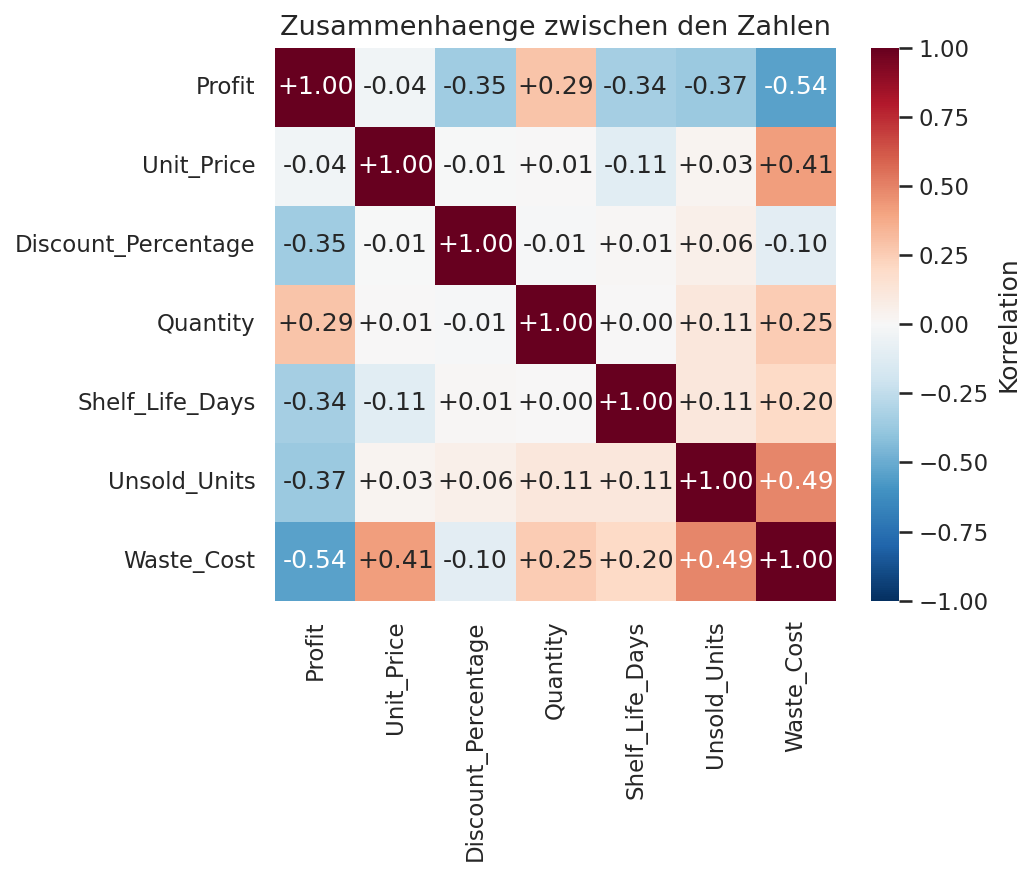

In [13]:
spalten = ["Profit", "Unit_Price", "Discount_Percentage", "Quantity",
           "Shelf_Life_Days", "Unsold_Units", "Waste_Cost"]
korr = df[spalten].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(korr, annot=True, fmt="+.2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Korrelation"})
ax.set_title("Zusammenhaenge zwischen den Zahlen")
plt.tight_layout()
plt.savefig("abbildungen/06_korrelation.png", dpi=130, bbox_inches="tight")
plt.show()

Die Heatmap zeigt Zusammenhänge zwischen den Variablen. Eine Korrelation beschreibt
eine gemeinsame Veränderung, belegt aber keine Ursache-Wirkung-Beziehung.

## 11. Zusammenfassung

- Die Bäckerei macht in diesen Daten insgesamt Verlust; rund die Hälfte der
  Verkaufspositionen ist defizitär und etwa ein Drittel der Ware bleibt übrig.
- **Getränke** sind am profitabelsten. Teure, schnell verderbliche Produkte
  (*Dairy*, *Spreads*, *Cakes*) sind am verlustträchtigsten.
- **Rabatte** senken den Gewinn deutlich, erhöhen die verkaufte Menge aber kaum.
- **Filiale, Wochentag und Jahreszeit** spielen nur eine kleine Rolle.

### Mögliche Handlungsempfehlungen
- Produktion von stark überschüssigen, verderblichen Produkten reduzieren.
- Rabatte gezielter und sparsamer einsetzen.
- Das profitable Getränkesortiment stärken.

### Grenzen der Untersuchung
Der Datensatz ist synthetisch. Die Muster gelten nur innerhalb dieser Daten
und sind nicht ohne Weiteres auf reale Bäckereien übertragbar.
